In [ ]:
import pandas as pd
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.preprocessing import StandardScaler
import matplotlib.pyplot as plt

df = pd.read_csv('/content/House_Price_dataset.csv')
df = df[df['purpose'] == 'For Sale'].copy()
df['Area'] = df['Area Size']
df.loc[df['Area Type'] == 'Kanal', 'Area'] = df['Area Size'] * 20
df = df[(df['Area'] > 0) & (df['price'] > 0)]
df = df[(df['Area'] < df['Area'].quantile(0.99)) & (df['price'] < df['price'].quantile(0.99))]

X = df[['Area', 'price']]
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

wcss = []
for k in range(1, 11):
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    km.fit(X_scaled)
    wcss.append(km.inertia_)

plt.plot(range(1, 11), wcss, marker='o')
plt.xlabel('Number of Clusters (K)')
plt.ylabel('WCSS')
plt.title('Elbow Method')
plt.show()

kmeans = KMeans(n_clusters=4, random_state=42, n_init=10)
df['Cluster'] = kmeans.fit_predict(X_scaled)
print(df['Cluster'].value_counts().sort_index())
print(df.groupby('Cluster')[['Area', 'price']].mean())

plt.scatter(df['Area'], df['price'], c=df['Cluster'], cmap='viridis')
centers = scaler.inverse_transform(kmeans.cluster_centers_)
plt.scatter(centers[:, 0], centers[:, 1], c='red', marker='X', s=200, label='Centroids')
plt.xlabel('Area (Marla)')
plt.ylabel('Price')
plt.title('House Segments (K-Means, K=4)')
plt.legend()
plt.show()

# Note: Hierarchical clustering on large datasets can be extremely slow and memory-intensive. 
# We will use AgglomerativeClustering on a subset or run it directly if dataset size permits. 
# Since df has over 118k rows, we sample a subset of 5000 rows for Agglomerative Clustering to prevent running out of memory.
df_sample = df.sample(5000, random_state=42).copy()
X_sample_scaled = scaler.transform(df_sample[['Area', 'price']])
hc = AgglomerativeClustering(n_clusters=4)
df_sample['HC_Cluster'] = hc.fit_predict(X_sample_scaled)

plt.scatter(df_sample['Area'], df_sample['price'], c=df_sample['HC_Cluster'], cmap='plasma')
plt.xlabel('Area Size')
plt.ylabel('Price')
plt.title('House Segments (Hierarchical Clustering - Sample)')
plt.show()

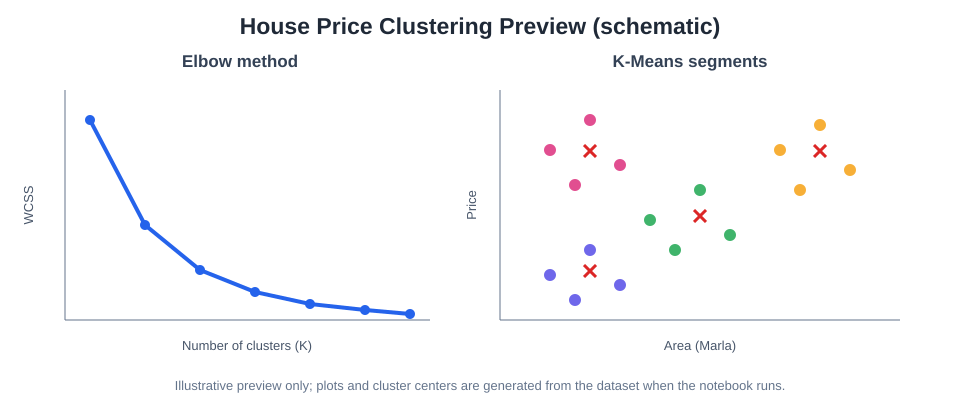

In [ ]:
# Clustering image preview (schematic; fitted plots appear when run)
from IPython.display import SVG, display
display(SVG(data="""<svg xmlns="http://www.w3.org/2000/svg" width="960" height="410" viewBox="0 0 960 410" role="img"><rect width="960" height="410" fill="#fff"/><text x="480" y="34" text-anchor="middle" font-family="Arial,sans-serif" font-size="23" font-weight="bold" fill="#1f2937">House Price Clustering Preview (schematic)</text><text x="240" y="67" text-anchor="middle" font-family="Arial,sans-serif" font-size="17" font-weight="bold" fill="#334155">Elbow method</text><path d="M65 320H430 M65 320V90" stroke="#64748b" fill="none"/><path d="M90 120 L145 225 L200 270 L255 292 L310 304 L365 310 L410 314" stroke="#2563eb" stroke-width="4" fill="none"/><g fill="#2563eb"><circle cx="90" cy="120" r="5"/><circle cx="145" cy="225" r="5"/><circle cx="200" cy="270" r="5"/><circle cx="255" cy="292" r="5"/><circle cx="310" cy="304" r="5"/><circle cx="365" cy="310" r="5"/><circle cx="410" cy="314" r="5"/></g><text x="247" y="350" text-anchor="middle" font-family="Arial,sans-serif" font-size="13" fill="#475569">Number of clusters (K)</text><text x="33" y="205" transform="rotate(-90 33 205)" text-anchor="middle" font-family="Arial,sans-serif" font-size="13" fill="#475569">WCSS</text><text x="690" y="67" text-anchor="middle" font-family="Arial,sans-serif" font-size="17" font-weight="bold" fill="#334155">K-Means segments</text><path d="M500 320H900 M500 320V90" stroke="#64748b" fill="none"/><g opacity=".82"><g fill="#4f46e5"><circle cx="550" cy="275" r="6"/><circle cx="590" cy="250" r="6"/><circle cx="620" cy="285" r="6"/><circle cx="575" cy="300" r="6"/></g><g fill="#16a34a"><circle cx="650" cy="220" r="6"/><circle cx="700" cy="190" r="6"/><circle cx="730" cy="235" r="6"/><circle cx="675" cy="250" r="6"/></g><g fill="#f59e0b"><circle cx="780" cy="150" r="6"/><circle cx="820" cy="125" r="6"/><circle cx="850" cy="170" r="6"/><circle cx="800" cy="190" r="6"/></g><g fill="#db2777"><circle cx="550" cy="150" r="6"/><circle cx="590" cy="120" r="6"/><circle cx="620" cy="165" r="6"/><circle cx="575" cy="185" r="6"/></g></g><g stroke="#dc2626" stroke-width="3"><path d="M584 265l12 12m0-12l-12 12M694 210l12 12m0-12l-12 12M814 145l12 12m0-12l-12 12M584 145l12 12m0-12l-12 12"/></g><text x="700" y="350" text-anchor="middle" font-family="Arial,sans-serif" font-size="13" fill="#475569">Area (Marla)</text><text x="476" y="205" transform="rotate(-90 476 205)" text-anchor="middle" font-family="Arial,sans-serif" font-size="13" fill="#475569">Price</text><text x="480" y="390" text-anchor="middle" font-family="Arial,sans-serif" font-size="13" fill="#64748b">Illustrative preview only; plots and cluster centers are generated from the dataset when the notebook runs.</text></svg>"""))


In [ ]:
import pandas as pd
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.preprocessing import StandardScaler
import matplotlib.pyplot as plt

df = pd.read_csv('/content/House_Price_dataset.csv')
df = df[df['purpose'] == 'For Sale'].copy()
df['Area'] = df['Area Size']
df.loc[df['Area Type'] == 'Kanal', 'Area'] = df['Area Size'] * 20
df = df[(df['Area'] > 0) & (df['price'] > 0)]
df = df[(df['Area'] < df['Area'].quantile(0.99)) & (df['price'] < df['price'].quantile(0.99))]

X = df[['Area', 'price']]
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

wcss = []
for k in range(1, 11):
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    km.fit(X_scaled)
    wcss.append(km.inertia_)

plt.plot(range(1, 11), wcss, marker='o')
plt.xlabel('Number of Clusters (K)')
plt.ylabel('WCSS')
plt.title('Elbow Method')
plt.show()

kmeans = KMeans(n_clusters=4, random_state=42, n_init=10)
df['Cluster'] = kmeans.fit_predict(X_scaled)
print(df['Cluster'].value_counts().sort_index())
print(df.groupby('Cluster')[['Area', 'price']].mean())

plt.scatter(df['Area'], df['price'], c=df['Cluster'], cmap='viridis')
centers = scaler.inverse_transform(kmeans.cluster_centers_)
plt.scatter(centers[:, 0], centers[:, 1], c='red', marker='X', s=200, label='Centroids')
plt.xlabel('Area (Marla)')
plt.ylabel('Price')
plt.title('House Segments (K-Means, K=4)')
plt.legend()
plt.show()

# Note: Hierarchical clustering on large datasets can be extremely slow and memory-intensive. 
# We will use AgglomerativeClustering on a subset or run it directly if dataset size permits. 
# Since df has over 118k rows, we sample a subset of 5000 rows for Agglomerative Clustering to prevent running out of memory.
df_sample = df.sample(5000, random_state=42).copy()
X_sample_scaled = scaler.transform(df_sample[['Area', 'price']])
hc = AgglomerativeClustering(n_clusters=4)
df_sample['HC_Cluster'] = hc.fit_predict(X_sample_scaled)

plt.scatter(df_sample['Area'], df_sample['price'], c=df_sample['HC_Cluster'], cmap='plasma')
plt.xlabel('Area Size')
plt.ylabel('Price')
plt.title('House Segments (Hierarchical Clustering - Sample)')
plt.show()